# Sinks: A CO<sub>2</sub> Price and Electricity Exports

The [basic tutorial](01_basic_tutorial.ipynb) used two sinks: the electricity demand, whose hourly operation is fixed (`operationRateFix`), and the CO<sub>2</sub> emitted into the environment, whose yearly sum is capped by a balance limit (`balanceLimitID`). This notebook changes the CO<sub>2</sub> sink and adds a new one:

| Component | New parameters | What they do |
|---|---|---|
| CO<sub>2</sub> to environment | `commodityCost` (on a sink) | puts a price on every tonne of CO<sub>2</sub> that leaves the system |
| Electricity export | `capacityFix` (on a sink) | limits the hourly export to the capacity of the cables to neighboring countries |
| | `commodityRevenue` | pays for every unit of electricity that leaves the system |

`commodityCost` and `commodityRevenue` work the same way for sources, where the commodity enters the system instead.

## 1. The model of the basic tutorial, without CO<sub>2</sub> limit

The function `buildBasicTutorialModel` in the file `tutorialHelpers.py` next to this notebook builds exactly the model of the basic tutorial. With `co2LimitPerPeriod=None`, it leaves out the CO<sub>2</sub> limit and the sink `"CO2 to environment"`, so that we can add a sink with a CO<sub>2</sub> price instead.

In [1]:
import warnings

import pandas as pd

import fine as fn
from tutorialHelpers import (
    CO2_LIMIT_PER_PERIOD,
    buildBasicTutorialModel,
    colormap,
    plotCapacityAndGeneration,
)

warnings.filterwarnings("ignore")  # keeps the output of this tutorial readable

esM = buildBasicTutorialModel(co2LimitPerPeriod=None)

## 2. A CO<sub>2</sub> price instead of a CO<sub>2</sub> limit

A limit fixes the amount of CO<sub>2</sub> and lets the optimization find the cheapest way to stay below it. A price works the other way round: it makes every tonne of CO<sub>2</sub> cost something and lets the optimization decide how much to emit. In FINE, a price is the **`commodityCost`** of the sink through which CO<sub>2</sub> leaves the system: every unit of its operation costs this amount.

The unit of `commodityCost` is `costUnit` per unit of the commodity, here million Euro per million tonnes of CO<sub>2</sub>, which is simply Euro per tonne. We assume a CO<sub>2</sub> price that rises from 30 Euro per tonne in 2020 to 150 in 2030 and 300 in 2040. (For prices that change every hour, `commodityCost` can also be a `pd.DataFrame` with one row per time step and one column per region, like the time series in the basic tutorial.)

In [2]:
esM.add(
    fn.Sink(
        esM=esM,
        name="CO2 to environment",
        commodity="CO2",
        hasCapacityVariable=False,
        commodityCost={2020: 30, 2030: 150, 2040: 300},  # Euro per tonne of CO2
    )
)

## 3. Electricity exports

Germany is connected to its neighboring countries by cables, through which it can sell electricity. We model the exports as a sink with two new parameters:

- **`capacityFix`**: a sink can have a capacity, just like a source. Here it is the capacity of the cables to the neighbors, which we assume to be 10 GW in each region. Its hourly operation (the export) can never be higher. Since the cables exist already, the sink has no investment cost.
- **`commodityRevenue`**: the revenue per unit of the commodity that leaves the system through this sink, here 30 Euro per MWh (0.03 million Euro per GWh). Revenues lower the total cost of the system.

A fixed price for every hour is a strong simplification. Real electricity prices change every hour; given as a `pd.DataFrame` with one row per time step, `commodityRevenue` lets a sink earn a different price in every hour.

In [3]:
esM.add(
    fn.Sink(
        esM=esM,
        name="Electricity export",
        commodity="electricity",
        hasCapacityVariable=True,
        capacityFix=pd.Series({"north": 10, "south": 10}),  # GW
        commodityRevenue=0.03,  # million Euro per GWh
    )
)

## 4. Optimize

In [4]:
esM.aggregateTemporally(n_clusters=8, segments=None)

In [5]:
esM.optimize(timeSeriesAggregation=True)

Set parameter OutputFlag to value 1


Set parameter Threads to value 3


Set parameter LogFile to value ""


Set parameter QCPDual to value 1


Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (win64 - Windows 11+.0 (26300.2))


CPU model: Intel(R) Core(TM) Ultra 7 255U, instruction set [SSE2|AVX|AVX2]


... (80 outputs left out)

Iteration    Objective       Primal Inf.    Dual Inf.      Time


    3475    5.4979969e+05   0.000000e+00   0.000000e+00      1s


Solved in 3475 iterations and 0.85 seconds (0.75 work units)


Optimal objective  5.497996927e+05


## 5. Results

### Emissions

The yearly emissions are the `operation` of the sink `"CO2 to environment"` in the optimization summary. Here they are next to the limit of the basic tutorial:

In [6]:
emissions = pd.DataFrame(index=esM.investmentPeriodNames)
for year in esM.investmentPeriodNames:
    summary = esM.getOptimizationSummary("SourceSinkModel", outputLevel=1, ip=year)
    operation = summary.xs("operation", level="Property").droplevel("Unit")
    emissions.loc[year, "With CO2 price [Mt]"] = operation.loc[
        "CO2 to environment"
    ].sum()
    emissions.loc[year, "Limit of the basic tutorial [Mt]"] = CO2_LIMIT_PER_PERIOD[year]

emissions.round(1)

,With CO2 price [Mt],Limit of the basic tutorial [Mt]
2020,176.2,90.0
2030,102.4,45.0
2040,56.3,20.0


With these prices, the emissions are much higher than with the limits of the basic tutorial. In 2020, 30 Euro per tonne are not enough to make wind turbines and PV cheaper than gas power plants, so the gas power plants produce almost all of the electricity (see the bar charts below). Only the higher prices of 2030 and 2040 lead to a large expansion of wind and PV. To stay within the limits of the basic tutorial, the CO<sub>2</sub> price would have to be much higher.

This is the main difference between the two approaches: a limit fixes the emissions and leaves the cost open, while a price fixes the cost per tonne and leaves the emissions open.

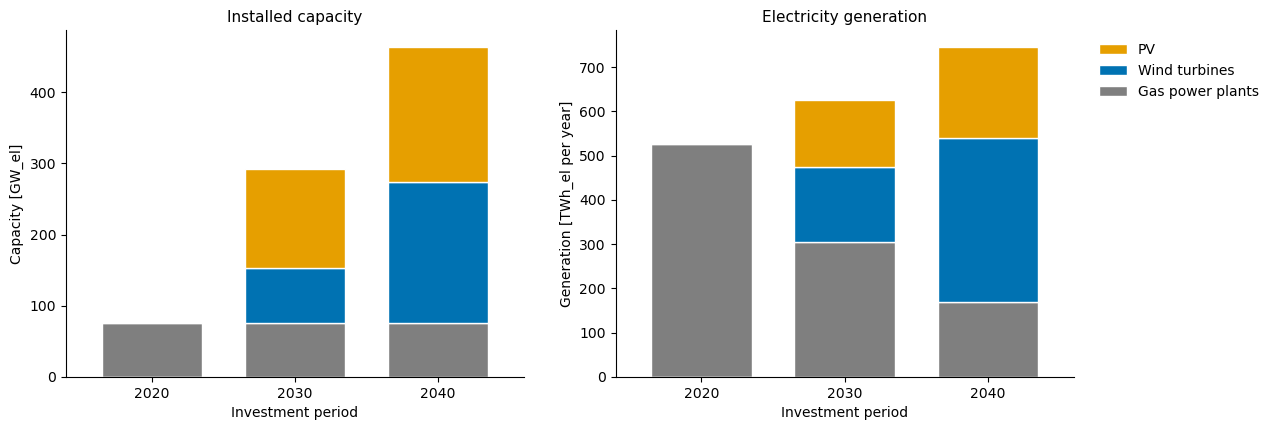

In [7]:
capacity, generation = plotCapacityAndGeneration(
    esM, ["Gas power plants", "Wind turbines", "PV"]
)

### Exports

The yearly exports per region:

In [8]:
exports = pd.DataFrame(
    {
        year: esM.getOptimizationSummary("SourceSinkModel", outputLevel=1, ip=year)
        .loc[("Electricity export", "operation")]
        .iloc[0]
        / 1000
        for year in esM.investmentPeriodNames
    }
).T
exports.columns.name = "Exports [TWh]"
exports.astype(float).round(1)

Exports [TWh],north,south
2020,0.0,0.0
2030,10.9,6.6
2040,21.7,16.2


No electricity is exported in 2020: 30 Euro per MWh is less than the cost of producing it in gas power plants (the gas alone costs 25/0.6 ≈ 42 Euro per MWh of electricity, plus the CO<sub>2</sub> price). Exports only start once wind turbines and PV are built. In 2040, about 22 TWh leave the north and about 16 TWh leave the south. This is electricity that could not be used in Germany at that moment and would otherwise be curtailed.

The heat map shows the exports of the north in 2040: around midday on many days of the year, when PV produces a lot, and on windy days in winter, often around the clock.

(<Figure size 900x300 with 2 Axes>,
 <Axes: xlabel='Day of the year', ylabel='Hour of the day'>)

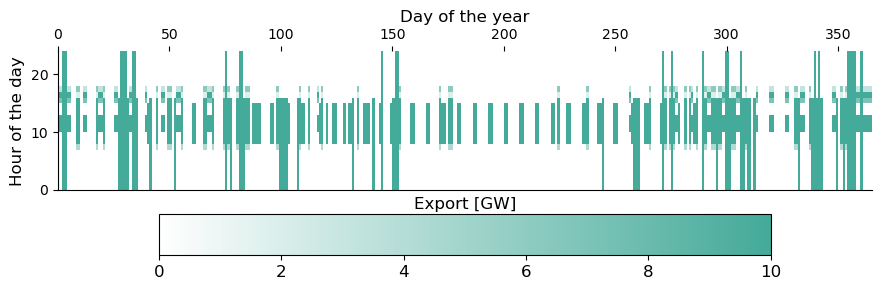

In [9]:
fn.plotOperationColorMap(
    esM,
    "Electricity export",
    "north",
    ip=2040,
    cmap=colormap("Electricity export"),
    figsize=(9, 3),
    xlabel="Day of the year",
    ylabel="Hour of the day",
    zlabel="Export [GW]",
)

## Things to try

- Raise the CO<sub>2</sub> price for 2040 until the emissions are as low as the limit of the basic tutorial (20 million tonnes).
- Raise the export revenue to 80 Euro per MWh. Does the system now build wind turbines and PV only for export?
- Keep the CO<sub>2</sub> price and add the CO<sub>2</sub> limit again (`balanceLimitID` and `balanceLimit` as in the basic tutorial). In which periods does the limit still matter?

The next notebook, [Conversions](13_conversions.ipynb), adds existing gas power plants and electrolyzers that produce hydrogen.